# FASTopic Replication

Each table shows the paper's FASTopic result, ours as mean ± SD over 5 seeds (laptop CPU), and the difference (ours − paper). The paper reports means only, and there is no agreed threshold for when a reproduced result counts as different. We treat a gap within one SD of ours as noise. Section 6 lists every larger gap and separates those clearly different (more than two SDs). Section 7 investigates them.

In [18]:
import os
from pathlib import Path
import pandas as pd

if Path.cwd().name == "notebooks":
    os.chdir("..")
R = Path("results")
M4 = ["CV", "TD", "Purity", "NMI"]

# Paper values (FASTopic rows)
MAIN = {"20NG": [0.412, 0.981, 0.570, 0.522], "NYT": [0.437, 0.999, 0.662, 0.369], # Tables 10-11
        "NeurIPS": [0.420, 0.996, None, None], "ACL": [0.413, 0.997, None, None],
        "Wikitext-103": [0.439, 0.992, None, None]}
ABLATION = { # (with ETP, without)
    50: {"20NG": ([0.426, 0.983, 0.577, 0.525], [0.368, 0.391, 0.401, 0.452]),  # Tables 6, 8
         "NYT": ([0.437, 0.999, 0.662, 0.369], [0.363, 0.338, 0.553, 0.294]),
         "NeurIPS": ([0.422, 0.998, None, None], [0.380, 0.216, None, None]),
         "ACL": ([0.420, 0.998, None, None], [0.373, 0.164, None, None]),
         "Wikitext-103": ([0.439, 0.992, None, None], [0.359, 0.335, None, None])},
    10: {"20NG": ([0.432, 1.000, 0.331, 0.437], [0.367, 0.571, 0.294, 0.408]), # Table 9
         "NYT": ([0.428, 1.000, 0.549, 0.316], [0.371, 0.620, 0.512, 0.263]),
         "NeurIPS": ([0.434, 1.000, None, None], [0.379, 0.512, None, None]),
         "ACL": ([0.442, 1.000, None, None], [0.364, 0.412, None, None]),
         "Wikitext-103": ([0.469, 1.000, None, None], [0.416, 0.660, None, None])}}
TRANSFER = {"20NG": [0.604, 0.593], "NYT": [0.754, 0.596]} # Figure 4 (right)
STABILITY = { # WoS: Tables 4-5, 13-16
    "topics K": {75: [0.465, 0.998, 0.689, 0.364], 100: [0.464, 0.993, 0.703, 0.368],
                 125: [0.460, 0.984, 0.710, 0.365], 150: [0.459, 0.972, 0.721, 0.368],
                 175: [0.458, 0.959, 0.735, 0.372], 200: [0.456, 0.949, 0.735, 0.368]},
    "docs N": {15000: [0.451, 0.999, 0.679, 0.369], 20000: [0.456, 1.000, 0.672, 0.364],
               25000: [0.458, 1.000, 0.672, 0.363], 30000: [0.455, 1.000, 0.671, 0.354],
               35000: [0.454, 1.000, 0.669, 0.353], 40000: [0.460, 1.000, 0.670, 0.351]},
    "vocab V": {20000: [0.470, 1.000, 0.673, 0.368], 30000: [0.467, 0.979, 0.676, 0.369],
                40000: [0.464, 0.934, 0.676, 0.373], 50000: [0.460, 0.917, 0.679, 0.376]}}
CPU_RUNNING = {"20NG": 95.93, "NYT": 112.96, "NeurIPS": 177.58, "ACL": 209.75, "Wikitext-103": 552.70}

ALL = [] # every paper-vs-ours comparison, for section 6

cv = pd.read_csv(R / "cv_palmetto.csv").drop_duplicates(["dataset", "K", "seed"])

def load(name):
    df = pd.read_csv(R / name).drop_duplicates(["dataset", "K", "seed"], keep="first")
    return df.merge(cv, on=["dataset", "K", "seed"], how="left")

def ours(df, dataset, k, metrics):
    """(mean, SD) over seeds for each metric; None if not available."""
    rows = df[(df.dataset == dataset) & (df.K == k)]
    out = []
    for m in metrics:
        v = rows[m].dropna() if m in rows else pd.Series(dtype=float)
        out.append((v.mean(), v.std()) if len(v) else None)
    return out

def compare(rows, metrics, labels=("paper", "ours"), diff=True, where=""):
    """rows: [(name, paper_values, ours(...))] -> paper | ours (mean ± SD) | diff (ours − paper)."""
    out = []
    for name, paper, mine in rows:
        r = {"": name}
        for m, p, o in zip(metrics, paper, mine):
            r[(m, labels[0])] = "" if p is None else f"{p:.3f}"
            r[(m, labels[1])] = "" if o is None else f"{o[0]:.3f} ± {o[1]:.3f}"
            if diff:
                r[(m, "diff")] = "" if p is None or o is None else f"{o[0] - p:+.3f}"
            if where and p is not None and o is not None:
                ALL.append({"section": where, "result": name, "metric": m, "paper": p,
                            "ours": o[0], "SD": o[1], "diff": o[0] - p})
        out.append(r)
    df = pd.DataFrame(out).set_index("")
    df.columns = pd.MultiIndex.from_tuples(df.columns)
    return df

main = load("fastopic_original.csv")

DIAG = R / "diagnostics"

## 1. Main results ($K = 50$)

Topic quality (CV, TD), clustering (Purity, NMI) from Tables 10–11, and classification (Acc, F1) from Figure 4 (left).

In [19]:
compare([(d, p, ours(main, d, 50, M4)) for d, p in MAIN.items()], M4, where="1")

CV                            TD                         \
              paper           ours    diff  paper           ours    diff   
                                                                           
20NG          0.412  0.417 ± 0.007  +0.005  0.981  0.993 ± 0.004  +0.012   
NYT           0.437  0.427 ± 0.009  -0.010  0.999  1.000 ± 0.001  +0.001   
NeurIPS       0.420  0.429 ± 0.004  +0.009  0.996  0.999 ± 0.001  +0.003   
ACL           0.413  0.411 ± 0.010  -0.002  0.997  0.998 ± 0.002  +0.001   
Wikitext-103  0.439  0.430 ± 0.007  -0.009  0.992  0.998 ± 0.002  +0.006   

             Purity                           NMI                         
              paper           ours    diff  paper           ours    diff  
                                                                          
20NG          0.570  0.587 ± 0.015  +0.017  0.522  0.528 ± 0.004  +0.006  
NYT           0.662  0.664 ± 0.006  +0.002  0.369  0.371 ± 0.003  +0.002  
NeurIPS                                                                   
ACL                                                                       
Wikitext-103

In [20]:
IN_DOMAIN = {"20NG": [0.705, 0.69], "NYT": [0.795, 0.65]}
compare([(d, p, ours(main, d, 50, ["Acc", "F1"])) for d, p in IN_DOMAIN.items()], ["Acc", "F1"], labels=("paper ≈", "ours"), where="1 (in-domain)")

Acc                             F1                       
     paper ≈           ours    diff paper ≈           ours    diff
                                                                  
20NG   0.705  0.694 ± 0.003  -0.011   0.690  0.680 ± 0.002  -0.010
NYT    0.795  0.777 ± 0.006  -0.018   0.650  0.590 ± 0.005  -0.060

**Notes:** Paper values read approximately from the bars in Figure 4 (left).

## 2. Ablation: is ETP needed? ($K = 50$ and $K = 10$)
"Without" replaces ETP with the softmax in Eq. (2) at $\tau = 1$. The paper does not give its temperature (see 7.4).

In [21]:
for k, table in ABLATION.items():
    w = main if k == 50 else load("ablation_k10.csv")
    wo = load("ablation_no_etp.csv") if k == 50 else w
    rows = []
    for d, (pw, pwo) in table.items():
        rows += [(f"{d} · with ETP", pw, ours(w, d, k, M4)),
                 (f"{d} · without", pwo, ours(wo, f"{d}-noETP", k, M4))]
    print(f"K = {k}")
    display(compare(rows, M4, where=f"2 (K = {k})"))

K = 50


CV                            TD                 \
                         paper           ours    diff  paper           ours   
                                                                              
20NG · with ETP          0.426  0.417 ± 0.007  -0.009  0.983  0.993 ± 0.004   
20NG · without           0.368  0.367 ± 0.004  -0.001  0.391  0.470 ± 0.011   
NYT · with ETP           0.437  0.427 ± 0.009  -0.010  0.999  1.000 ± 0.001   
NYT · without            0.363  0.368 ± 0.008  +0.005  0.338  0.421 ± 0.013   
NeurIPS · with ETP       0.422  0.429 ± 0.004  +0.007  0.998  0.999 ± 0.001   
NeurIPS · without        0.380  0.380 ± 0.006  +0.000  0.216  0.268 ± 0.019   
ACL · with ETP           0.420  0.411 ± 0.010  -0.009  0.998  0.998 ± 0.002   
ACL · without            0.373  0.374 ± 0.006  +0.001  0.164  0.227 ± 0.017   
Wikitext-103 · with ETP  0.439  0.430 ± 0.007  -0.009  0.992  0.998 ± 0.002   
Wikitext-103 · without   0.359  0.362 ± 0.004  +0.003  0.335  0.418 ± 0.022   

                                Purity                           NMI  \
                           diff  paper           ours    diff  paper   
                                                                       
20NG · with ETP          +0.010  0.577  0.587 ± 0.015  +0.010  0.525   
20NG · without           +0.079  0.401  0.416 ± 0.029  +0.015  0.452   
NYT · with ETP           +0.001  0.662  0.664 ± 0.006  +0.002  0.369   
NYT · without            +0.083  0.553  0.569 ± 0.010  +0.016  0.294   
NeurIPS · with ETP       +0.001                                        
NeurIPS · without        +0.052                                        
ACL · with ETP           +0.000                                        
ACL · without            +0.063                                        
Wikitext-103 · with ETP  +0.006                                        
Wikitext-103 · without   +0.083                                        

                                                
                                  ours    diff  
                                                
20NG · with ETP          0.528 ± 0.004  +0.003  
20NG · without           0.459 ± 0.022  +0.007  
NYT · with ETP           0.371 ± 0.003  +0.002  
NYT · without            0.307 ± 0.011  +0.013  
NeurIPS · with ETP                              
NeurIPS · without                               
ACL · with ETP                                  
ACL · without                                   
Wikitext-103 · with ETP                         
Wikitext-103 · without

K = 10


CV                            TD                 \
                         paper           ours    diff  paper           ours   
                                                                              
20NG · with ETP          0.432  0.426 ± 0.012  -0.006  1.000  1.000 ± 0.000   
20NG · without           0.367  0.360 ± 0.014  -0.007  0.571  0.740 ± 0.049   
NYT · with ETP           0.428  0.414 ± 0.016  -0.014  1.000  1.000 ± 0.000   
NYT · without            0.371  0.379 ± 0.015  +0.008  0.620  0.757 ± 0.027   
NeurIPS · with ETP       0.434  0.446 ± 0.032  +0.012  1.000  1.000 ± 0.000   
NeurIPS · without        0.379  0.381 ± 0.010  +0.002  0.512  0.697 ± 0.038   
ACL · with ETP           0.442  0.440 ± 0.020  -0.002  1.000  1.000 ± 0.000   
ACL · without            0.364  0.363 ± 0.015  -0.001  0.412  0.616 ± 0.050   
Wikitext-103 · with ETP  0.469  0.468 ± 0.013  -0.001  1.000  1.000 ± 0.000   
Wikitext-103 · without   0.416  0.423 ± 0.011  +0.007  0.660  0.767 ± 0.023   

                                Purity                           NMI  \
                           diff  paper           ours    diff  paper   
                                                                       
20NG · with ETP          +0.000  0.331  0.343 ± 0.007  +0.012  0.437   
20NG · without           +0.169  0.294  0.271 ± 0.012  -0.023  0.408   
NYT · with ETP           +0.000  0.549  0.537 ± 0.036  -0.012  0.316   
NYT · without            +0.137  0.512  0.518 ± 0.030  +0.006  0.263   
NeurIPS · with ETP       +0.000                                        
NeurIPS · without        +0.185                                        
ACL · with ETP           +0.000                                        
ACL · without            +0.204                                        
Wikitext-103 · with ETP  +0.000                                        
Wikitext-103 · without   +0.107                                        

                                                
                                  ours    diff  
                                                
20NG · with ETP          0.464 ± 0.009  +0.027  
20NG · without           0.375 ± 0.012  -0.033  
NYT · with ETP           0.308 ± 0.030  -0.008  
NYT · without            0.272 ± 0.011  +0.009  
NeurIPS · with ETP                              
NeurIPS · without                               
ACL · with ETP                                  
ACL · without                                   
Wikitext-103 · with ETP                         
Wikitext-103 · without

## 3. Transferability: train on Wikitext-103, classify 20NG and NYT

The paper's values are from Figure 4 (right).

In [22]:
tr = pd.read_csv(R / "transfer.csv").rename(columns={"target": "dataset"})
compare([(d, p, ours(tr, d, 50, ["Acc", "F1"])) for d, p in TRANSFER.items()], ["Acc", "F1"], where="3")

Acc                            F1                       
      paper           ours    diff  paper           ours    diff
                                                                
20NG  0.604  0.631 ± 0.009  +0.027  0.593  0.617 ± 0.009  +0.024
NYT   0.754  0.741 ± 0.004  -0.013  0.596  0.546 ± 0.013  -0.050

## 4. Stability: number of topics $K$, documents $N$, vocabulary $V$
The paper uses WoS, which is unavailable, so ours is on DBpedia. Lines show the change from the first setting.

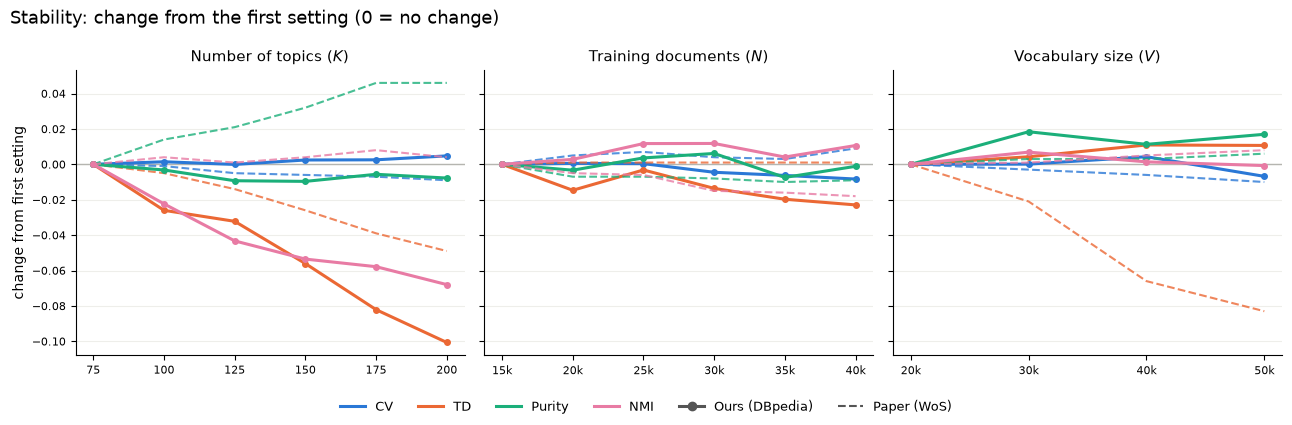

In [23]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

st = load("stability.csv")
COLORS = {"CV": "#2a78d6", "TD": "#eb6834", "Purity": "#1baf7a", "NMI": "#e87ba4"}
TITLES = {"topics K": "Number of topics ($K$)", "docs N": "Training documents ($N$)", "vocab V": "Vocabulary size ($V$)"}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, (setting, table) in zip(axes, STABILITY.items()):
    xs = list(table)
    paper = list(table.values())
    names = [{"topics K": "DBpedia", "docs N": f"DBpedia-N{x}", "vocab V": f"DBpedia-V{x}"}[setting] for x in xs]
    mine = [[v[0] for v in ours(st, n, x if setting == "topics K" else 50, M4)] for n, x in zip(names, xs)]
    ax.axhline(0, color="#b5b5b0", lw=1)
    for r, m in enumerate(M4):
        ax.plot(xs, [p[r] - paper[0][r] for p in paper], color=COLORS[m], lw=1.5, ls="--", alpha=0.8)
        ax.plot(xs, [o[r] - mine[0][r] for o in mine], color=COLORS[m], lw=2.2, marker="o", ms=4)
    ax.set_title(TITLES[setting], fontsize=11)
    ax.set_xticks(xs, [f"{x//1000}k" if x >= 1000 else str(x) for x in xs])
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#eeeeea", lw=0.8)
    ax.tick_params(labelsize=8)
axes[0].set_ylabel("change from first setting")
handles = [Line2D([], [], color=c, lw=2.2, label=m) for m, c in COLORS.items()] + \
          [Line2D([], [], color="#555", lw=2.2, marker="o", label="Ours (DBpedia)"),
           Line2D([], [], color="#555", lw=1.5, ls="--", label="Paper (WoS)")]
fig.legend(handles=handles, loc="lower center", ncol=6, frameon=False, fontsize=9)
fig.suptitle("Stability: change from the first setting (0 = no change)", fontsize=13, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.07, 1, 1))

## 5. Running time ($K = 50$)

In [24]:
raw = pd.read_csv(R / "fastopic_original.csv").query("K == 50")
t = raw.groupby("dataset").agg(embed_s=("embed_s", "max"), train_s=("train_s", "mean")).loc[list(CPU_RUNNING)]
t["ours_total_s"] = t.embed_s + t.train_s
t["paper_cpu_s"] = pd.Series(CPU_RUNNING)
t["diff_s"] = t.ours_total_s - t.paper_cpu_s
t.round(1)

,embed_s,train_s,ours_total_s,paper_cpu_s,diff_s
dataset,,,,,
20NG,35.6,63.0,98.6,95.9,2.7
NYT,41.1,58.9,100.0,113.0,-13.0
NeurIPS,50.7,74.5,125.2,177.6,-52.4
ACL,70.8,94.4,165.2,209.8,-44.6
Wikitext-103,199.5,764.4,963.9,552.7,411.2


**Notes:** Paper times are the CPU times the authors reported on OpenReview. Timed as in the paper (Sec. 4.4), from the end of data loading to the end of training, so ours include embedding (done once per dataset) plus the mean training time over 5 seeds.

## 6. Differences from the paper
### 6.1. Gaps larger than our SD
Gaps within one SD of ours, $|\Delta| \le s$, are treated as noise and not listed. Every other gap is below, with its size in SDs.

In [25]:
gaps = pd.DataFrame(ALL).drop_duplicates(["section", "result", "metric"])
gaps["|Δ| / s"] = (gaps["diff"].abs() / gaps.SD).where(gaps["diff"] != 0, 0)   # 0 ± 0 counts as equal
gaps["group"] = pd.cut(gaps["|Δ| / s"], [-1, 1, 2, float("inf")], labels=["noise", "1–2 SD", "> 2 SD"])
print(gaps.group.value_counts().reindex(["noise", "1–2 SD", "> 2 SD"]).to_string())
beyond = gaps[gaps.group != "noise"].set_index(["section", "result", "metric"]).round(3)
beyond.sort_values(["group", "|Δ| / s"], ascending=[True, False])

group
noise     37
1–2 SD    14
> 2 SD    27


paper   ours     SD   diff  \
section       result                  metric                               
2 (K = 50)    NeurIPS · with ETP      CV      0.422  0.429  0.004  0.007   
2 (K = 10)    20NG · without          Purity  0.294  0.271  0.012 -0.023   
              20NG · with ETP         Purity  0.331  0.343  0.007  0.012   
2 (K = 50)    NYT · without           Purity  0.553  0.569  0.010  0.016   
1             20NG                    NMI     0.522  0.528  0.004  0.006   
2 (K = 50)    20NG · with ETP         CV      0.426  0.417  0.007 -0.009   
1             NYT                     TD      0.999  1.000  0.001  0.001   
2 (K = 50)    NYT · with ETP          TD      0.999  1.000  0.001  0.001   
              NYT · without           NMI     0.294  0.307  0.011  0.013   
1             Wikitext-103            CV      0.439  0.430  0.007 -0.009   
2 (K = 50)    Wikitext-103 · with ETP CV      0.439  0.430  0.007 -0.009   
1             NYT                     CV      0.437  0.427  0.009 -0.010   
2 (K = 50)    NYT · with ETP          CV      0.437  0.427  0.009 -0.010   
1             20NG                    Purity  0.570  0.587  0.015  0.017   
1 (in-domain) NYT                     F1      0.650  0.590  0.005 -0.060   
2 (K = 50)    20NG · without          TD      0.391  0.470  0.011  0.079   
              NYT · without           TD      0.338  0.421  0.013  0.083   
2 (K = 10)    NYT · without           TD      0.620  0.757  0.027  0.137   
              NeurIPS · without       TD      0.512  0.697  0.038  0.185   
1             NeurIPS                 TD      0.996  0.999  0.001  0.003   
2 (K = 10)    Wikitext-103 · without  TD      0.660  0.767  0.023  0.107   
1 (in-domain) 20NG                    F1      0.690  0.680  0.002 -0.010   
2 (K = 10)    ACL · without           TD      0.412  0.616  0.050  0.204   
3             NYT                     F1      0.596  0.546  0.013 -0.050   
1 (in-domain) 20NG                    Acc     0.705  0.694  0.003 -0.011   
2 (K = 50)    Wikitext-103 · without  TD      0.335  0.418  0.022  0.083   
              ACL · without           TD      0.164  0.227  0.017  0.063   
2 (K = 10)    20NG · without          TD      0.571  0.740  0.049  0.169   
1             Wikitext-103            TD      0.992  0.998  0.002  0.006   
2 (K = 50)    Wikitext-103 · with ETP TD      0.992  0.998  0.002  0.006   
2 (K = 10)    20NG · with ETP         NMI     0.437  0.464  0.009  0.027   
3             NYT                     Acc     0.754  0.741  0.004 -0.013   
              20NG                    Acc     0.604  0.631  0.009  0.027   
1             20NG                    TD      0.981  0.993  0.004  0.012   
1 (in-domain) NYT                     Acc     0.795  0.777  0.006 -0.018   
2 (K = 10)    20NG · without          NMI     0.408  0.375  0.012 -0.033   
2 (K = 50)    NeurIPS · without       TD      0.216  0.268  0.019  0.052   
3             20NG                    F1      0.593  0.617  0.009  0.024   
2 (K = 50)    20NG · with ETP         TD      0.983  0.993  0.004  0.010   
1             NeurIPS                 CV      0.420  0.429  0.004  0.009   
2 (K = 50)    NeurIPS · with ETP      TD      0.998  0.999  0.001  0.001   

                                              |Δ| / s   group  
section       result                  metric                   
2 (K = 50)    NeurIPS · with ETP      CV        1.828  1–2 SD  
2 (K = 10)    20NG · without          Purity    1.823  1–2 SD  
              20NG · with ETP         Purity    1.635  1–2 SD  
2 (K = 50)    NYT · without           Purity    1.601  1–2 SD  
1             20NG                    NMI       1.440  1–2 SD  
2 (K = 50)    20NG · with ETP         CV        1.309  1–2 SD  
1             NYT                     TD        1.230  1–2 SD  
2 (K = 50)    NYT · with ETP          TD        1.230  1–2 SD  
              NYT · without           NMI       1.180  1–2 SD  
1             Wikitext-103            CV        1.174  1–2 SD  
2 (K = 50

### 6.2. Clearly different results
A gap of one to two SDs, $s < |\Delta| \le 2s$, is within normal variation: about 95% of run-to-run variation falls within two SDs, and the paper's mean comes from only 5 runs, so it carries noise too. We count these as reproduced. This assumes the paper's runs varied about as much as ours; with 5 seeds our SD is itself approximate.

Gaps of more than two SDs, $|\Delta| > 2s$, are clearly different:

In [26]:
beyond[beyond.group == "> 2 SD"].drop(columns="group").sort_values("|Δ| / s", ascending=False)

paper   ours     SD   diff  \
section       result                  metric                               
1 (in-domain) NYT                     F1      0.650  0.590  0.005 -0.060   
2 (K = 50)    20NG · without          TD      0.391  0.470  0.011  0.079   
              NYT · without           TD      0.338  0.421  0.013  0.083   
2 (K = 10)    NYT · without           TD      0.620  0.757  0.027  0.137   
              NeurIPS · without       TD      0.512  0.697  0.038  0.185   
1             NeurIPS                 TD      0.996  0.999  0.001  0.003   
2 (K = 10)    Wikitext-103 · without  TD      0.660  0.767  0.023  0.107   
1 (in-domain) 20NG                    F1      0.690  0.680  0.002 -0.010   
2 (K = 10)    ACL · without           TD      0.412  0.616  0.050  0.204   
3             NYT                     F1      0.596  0.546  0.013 -0.050   
1 (in-domain) 20NG                    Acc     0.705  0.694  0.003 -0.011   
2 (K = 50)    Wikitext-103 · without  TD      0.335  0.418  0.022  0.083   
              ACL · without           TD      0.164  0.227  0.017  0.063   
2 (K = 10)    20NG · without          TD      0.571  0.740  0.049  0.169   
2 (K = 50)    Wikitext-103 · with ETP TD      0.992  0.998  0.002  0.006   
1             Wikitext-103            TD      0.992  0.998  0.002  0.006   
2 (K = 10)    20NG · with ETP         NMI     0.437  0.464  0.009  0.027   
3             NYT                     Acc     0.754  0.741  0.004 -0.013   
              20NG                    Acc     0.604  0.631  0.009  0.027   
1             20NG                    TD      0.981  0.993  0.004  0.012   
1 (in-domain) NYT                     Acc     0.795  0.777  0.006 -0.018   
2 (K = 10)    20NG · without          NMI     0.408  0.375  0.012 -0.033   
2 (K = 50)    NeurIPS · without       TD      0.216  0.268  0.019  0.052   
3             20NG                    F1      0.593  0.617  0.009  0.024   
2 (K = 50)    20NG · with ETP         TD      0.983  0.993  0.004  0.010   
1             NeurIPS                 CV      0.420  0.429  0.004  0.009   
2 (K = 50)    NeurIPS · with ETP      TD      0.998  0.999  0.001  0.001   

                                              |Δ| / s  
section       result                  metric           
1 (in-domain) NYT                     F1       12.386  
2 (K = 50)    20NG · without          TD        7.079  
              NYT · without           TD        6.596  
2 (K = 10)    NYT · without           TD        5.102  
              NeurIPS · without       TD        4.892  
1             NeurIPS                 TD        4.747  
2 (K = 10)    Wikitext-103 · without  TD        4.619  
1 (in-domain) 20NG                    F1        4.246  
2 (K = 10)    ACL · without           TD        4.078  
3             NYT                     F1        3.880  
1 (in-domain) 20NG                    Acc       3.829  
2 (K = 50)    Wikitext-103 · without  TD        3.827  
              ACL · without           TD        3.804  
2 (K = 10)    20NG · without          TD        3.434  
2 (K = 50)    Wikitext-103 · with ETP TD        3.221  
1             Wikitext-103            TD        3.221  
2 (K = 10)    20NG · with ETP         NMI       3.178  
3             NYT                     Acc       3.178  
              20NG                    Acc       3.021  
1             20NG                    TD        2.916  
1 (in-domain) NYT                     Acc       2.865  
2 (K = 10)    20NG · without          NMI       2.818  
2 (K = 50)    NeurIPS · without       TD        2.802  
3             20NG                    F1        2.580  
2 (K = 50)    20NG · with ETP         TD        2.410  
1             NeurIPS                 CV        2.371  
2 (K = 50)    NeurIPS · with ETP      TD        2.008

They fall into eight groups, each investigated in Section 7. The last three are not single values in the table above: two are trends across settings, and running time has no SD.

| group | results | ours − paper | investigated in |
|---|---|---|---|
| NYT macro F1 | in-domain, transfer | −0.060, −0.050 | 7.2 |
| In-domain values read from a bar chart | 20NG Acc and F1, NYT Acc | −0.010 to −0.018 | 7.3 |
| Results without ETP | TD on all datasets; 20NG NMI at $K = 10$ | TD +0.052 to +0.204; NMI −0.033 | 7.4 |
| TD with ETP, near its maximum of 1 | 20NG, NeurIPS, Wikitext-103 (Sections 1 and 2) | +0.001 to +0.012 | 7.5 |
| Remaining small gaps | NeurIPS CV; transfer 20NG Acc/F1 and NYT Acc; 20NG NMI with ETP at $K = 10$ | −0.013 to +0.027 | 7.6 |
| NMI falls as $K$ grows | stability | ours falls, paper flat | 7.7 |
| TD stays flat as $V$ grows | stability | ours flat, paper falls | 7.8 |
| Running time | Wikitext-103 | +411 s | 7.9 |

The "with ETP" rows in Section 2 repeat the Section 1 results against the paper's ablation tables, so some gaps appear twice.

## 7. Investigation

### 7.1. Are our own results stable?
Before explaining any gap, we ruled out noise on our side: 24 replication runs (20NG, NYT and DBpedia at $K$ = 75 and 200 with all 5 seeds; one seed each of Wikitext-103 and the without-ETP runs) were run again from scratch with the same seeds.

In [27]:
first = pd.concat([pd.read_csv(R / f) for f in ["fastopic_original.csv", "ablation_no_etp.csv",
                                                "ablation_k10.csv", "stability.csv"]])
first = first.drop_duplicates(["dataset", "K", "seed"])
again = pd.read_csv(R / "rerun.csv").drop_duplicates(["dataset", "K", "seed"])
both = again.merge(first, on=["dataset", "K", "seed"], suffixes=(" rerun", " first"))
METRICS = ["TD", "Purity", "NMI", "Acc", "F1"]

rows = []
for (d, k), g in both.groupby(["dataset", "K"]):
    r = {"dataset": d, "K": k, "seeds": len(g)}
    for m in METRICS:
        r[f"{m} first"], r[f"{m} rerun"] = g[f"{m} first"].mean(), g[f"{m} rerun"].mean()
    r["max |diff|"] = pd.concat([(g[f"{m} rerun"] - g[f"{m} first"]).abs() for m in METRICS]).max()
    rows.append(r)
pd.DataFrame(rows).set_index(["dataset", "K"]).round(3).fillna("")

seeds  TD first  TD rerun Purity first Purity rerun  \
dataset            K                                                          
20NG               50       5     0.993     0.993        0.587        0.587   
20NG-noETP         50       1     0.467     0.467        0.372        0.372   
DBpedia            75       5     0.967     0.967        0.852        0.852   
                   200      5     0.867     0.867        0.844        0.844   
NYT                50       5     1.000     1.000        0.664        0.664   
NYT-noETP          50       1     0.407     0.407        0.575        0.575   
Wikitext-103       50       1     0.999     0.999                             
Wikitext-103-noETP 50       1     0.387     0.387                             

                       NMI first NMI rerun Acc first Acc rerun F1 first  \
dataset            K                                                      
20NG               50      0.528     0.528     0.694     0.694     0.68   
20NG-noETP         50      0.426     0.426     0.574     0.574    0.555   
DBpedia            75      0.665     0.665     0.951     0.951    0.951   
                   200     0.597     0.597     0.955     0.955    0.955   
NYT                50      0.371     0.371     0.777     0.777     0.59   
NYT-noETP          50      0.305     0.305     0.678     0.678     0.41   
Wikitext-103       50                                                     
Wikitext-103-noETP 50                                                     

                       F1 rerun  max |diff|  
dataset            K                         
20NG               50      0.68         0.0  
20NG-noETP         50     0.555         0.0  
DBpedia            75     0.951         0.0  
                   200    0.955         0.0  
NYT                50      0.59         0.0  
NYT-noETP          50      0.41         0.0  
Wikitext-103       50                   0.0  
Wikitext-103-noETP 50                   0.0

**Conclusion:** Every rerun gives exactly the same numbers (largest difference 0.000), so the gaps in 6.2 are not chance on our side.

### 7.2. NYT macro F1
Figure 4 reports macro F1, which averages the F1 of each class equally:

$$\text{F1}_{\text{macro}} = \frac{1}{C}\sum_{c=1}^{C}\text{F1}_c \qquad\qquad \text{F1}_{\text{weighted}} = \sum_{c=1}^{C}\frac{n_c}{N}\,\text{F1}_c$$

where $C$ is the number of classes, $n_c$ the test documents in class $c$ and $N$ the total.

In [28]:
def acc_f1(df):
    r = df[(df.dataset == "NYT") & (df.K == 50)]
    return {m: f"{r[m].mean():.3f} ± {r[m].std():.3f}" for m in ["Acc", "F1"]}

pd.DataFrame({"paper ≈ (Fig. 4 left)": {"Acc": "0.795", "F1": "0.650"},
              "first run": acc_f1(main),
              "rerun": acc_f1(pd.read_csv(R / "rerun.csv"))}).T

,Acc,F1
paper ≈ (Fig. 4 left),0.795,0.650
first run,0.777 ± 0.006,0.590 ± 0.005
rerun,0.777 ± 0.006,0.590 ± 0.005


In [36]:
f1 = pd.read_csv(DIAG / "f1_by_seed.csv")
f1.groupby("dataset")[["Acc", "F1 macro", "F1 weighted", "F1 micro"]].mean().round(3)

,Acc,F1 macro,F1 weighted,F1 micro
dataset,,,,
20NG,0.694,0.68,0.691,0.694
NYT,0.777,0.59,0.767,0.777


In [30]:
pc = pd.read_csv(DIAG / "f1_per_class.csv")
pc[pc.dataset == "NYT"].sort_values("test docs").head(5)

,dataset,class,test docs,F1
5,NYT,5,7,0.000
8,NYT,8,7,0.000
2,NYT,2,13,0.615
9,NYT,9,19,0.500
3,NYT,3,30,0.554


**Conclusion:** Two NYT classes have only $n_c = 7$ test documents each and get $\text{F1}_c = 0$. In the macro average each counts as $\frac{1}{12}$ of the score, as much as the class with 280 documents. Weighted F1 (0.767) is close to accuracy (0.777), so the classifier works overall; the gap comes from two tiny classes, where a few documents swing the score. The transfer F1 on NYT (Section 3) has the same cause.

### 7.3. In-domain values read from a bar chart
Figure 4 (left) gives no numbers, so the paper values in Section 1 were read from the bars by eye, to about $\pm 0.01$. Our SD ($0.002$–$0.006$) is smaller than that reading error, so the two-SD test is stricter than these values support.

**Conclusion:** The 20NG gaps ($-0.011$, $-0.010$) are within reading error. NYT accuracy ($-0.018$) is just outside it; it is in the same direction as the NYT F1 gap (7.2), and the paper reports no exact value to compare against.

### 7.4. Results without ETP
Without ETP, topics come from a softmax over distances:

$$\theta_{ik} = \frac{\exp(-d_{ik}/\tau)}{\sum_{k'}\exp(-d_{ik'}/\tau)}$$

The paper does not report the temperature $\tau$; Section 2 uses $\tau = 1$. We reran the ablation at $\tau = 0.5, 1, 1.5, 2$ on 20NG and NYT ($K = 50$). "paper" is the paper's without-ETP row.


In [31]:
temp = pd.concat([load("ablation_no_etp.csv"), load("ablation_temp.csv")])
TAUS = {0.5: "-tau0.5", 1: "", 1.5: "-tau1.5", 2: "-tau2"}                           # tag in the run name
rows = [(f"{d} · τ = {tau}", ABLATION[50][d][1], ours(temp, f"{d}-noETP{tag}", 50, M4))
        for d in ["20NG", "NYT"] for tau, tag in TAUS.items()]
compare(rows, M4)

CV                            TD                         \
                paper           ours    diff  paper           ours    diff   
                                                                             
20NG · τ = 0.5  0.368  0.371 ± 0.004  +0.003  0.391  0.652 ± 0.009  +0.261   
20NG · τ = 1    0.368  0.367 ± 0.004  -0.001  0.391  0.470 ± 0.011  +0.079   
20NG · τ = 1.5  0.368  0.364 ± 0.005  -0.004  0.391  0.319 ± 0.022  -0.072   
20NG · τ = 2    0.368  0.365 ± 0.006  -0.003  0.391  0.146 ± 0.031  -0.245   
NYT · τ = 0.5   0.363  0.383 ± 0.005  +0.020  0.338  0.665 ± 0.018  +0.327   
NYT · τ = 1     0.363  0.368 ± 0.008  +0.005  0.338  0.421 ± 0.013  +0.083   
NYT · τ = 1.5   0.363  0.341 ± 0.005  -0.022  0.338  0.215 ± 0.024  -0.123   
NYT · τ = 2     0.363  0.332 ± 0.005  -0.031  0.338  0.053 ± 0.018  -0.285   

               Purity                           NMI                         
                paper           ours    diff  paper           ours    diff  
                                                                            
20NG · τ = 0.5  0.401  0.496 ± 0.015  +0.095  0.452  0.477 ± 0.008  +0.025  
20NG · τ = 1    0.401  0.416 ± 0.029  +0.015  0.452  0.459 ± 0.022  +0.007  
20NG · τ = 1.5  0.401  0.322 ± 0.018  -0.079  0.452  0.425 ± 0.020  -0.027  
20NG · τ = 2    0.401  0.183 ± 0.031  -0.218  0.452  0.320 ± 0.027  -0.132  
NYT · τ = 0.5   0.553  0.644 ± 0.009  +0.091  0.294  0.357 ± 0.011  +0.063  
NYT · τ = 1     0.553  0.569 ± 0.010  +0.016  0.294  0.307 ± 0.011  +0.013  
NYT · τ = 1.5   0.553  0.531 ± 0.011  -0.022  0.294  0.258 ± 0.020  -0.036  
NYT · τ = 2     0.553  0.329 ± 0.040  -0.224  0.294  0.064 ± 0.040  -0.230

**Conclusion:** All eight paper values (CV, TD, Purity, NMI on 20NG and NYT) lie between our $\tau = 1$ and $\tau = 1.5$ results. For example, the paper's 20NG TD of 0.391 lies between 0.470 ($\tau = 1$) and 0.319 ($\tau = 1.5$). So the gaps come from the unreported $\tau$, not from FASTopic. At every $\tau$, ETP gives much higher TD than the softmax (0.993 vs at most 0.652 on 20NG), so the paper's conclusion that ETP is needed holds. We ran the sweep at $K = 50$ only; the larger gaps at $K = 10$ are likely the same effect, but we did not test this.

### 7.5. TD with ETP, near its maximum

$$\text{TD} = \frac{\text{unique words among all topics' top } T \text{ words}}{K \cdot T}$$

TD with ETP is close to 1, so the SD is tiny and a few words look large in SD terms. Counting repeated words, $(1 - \text{TD}) \cdot K \cdot T$, makes the size concrete.

In [32]:
T = len((R / "topwords" / "20NG_K50_seed0.txt").read_text().splitlines()[0].split())
rows = []
for d in ["20NG", "NeurIPS", "Wikitext-103"]:
    td = ours(main, d, 50, ["TD"])[0][0]
    rows.append({"dataset": d, "paper TD": MAIN[d][1], "ours TD": round(td, 3),
                 "repeated words, paper": round((1 - MAIN[d][1]) * 50 * T),
                 "repeated words, ours": round((1 - td) * 50 * T)})
print(f"K = 50 topics × T = {T} words = {50 * T} topic words")
pd.DataFrame(rows).set_index("dataset")

K = 50 topics × T = 15 words = 750 topic words


,paper TD,ours TD,"repeated words, paper","repeated words, ours"
dataset,,,,
20NG,0.981,0.993,14,6
NeurIPS,0.996,0.999,3,0
Wikitext-103,0.992,0.998,6,2


**Conclusion:** The gaps are a handful of repeated words out of all topic words, and ours are the more diverse. We found no specific cause; at this size it does not change any conclusion.

### 7.6. Remaining small gaps

| result | ours − paper | our SD |
|---|---|---|
| NeurIPS CV (Section 1) | $+0.009$ | $0.004$ |
| 20NG Acc / F1, transfer (Section 3) | $+0.027$ / $+0.024$ | $0.009$ |
| NYT Acc, transfer (Section 3) | $-0.013$ | $0.004$ |
| 20NG NMI with ETP, $K = 10$ (Section 2) | $+0.027$ | $0.009$ |

The paper's own numbers vary by a similar amount: its 20NG result at $K = 50$ is CV 0.412 in Table 10 but 0.426 in Table 6, a gap of 0.014 between two tables of the same model.

**Conclusion:** These gaps are at most 0.027, three of the four are in our favour, and none changes the paper's conclusions. We found no specific cause. The paper does not report library versions or the classifier settings for transfer, and its own results vary by a similar amount between tables.

### 7.7. NMI falls as $K$ grows

$$\text{NMI} = \frac{I(Y;C)}{\tfrac{1}{2}\big[H(Y) + H(C)\big]} \qquad\qquad \text{NMI}_{\min} = \frac{I(Y;C)}{\min\big(H(Y),\,H(C)\big)}$$

$I(Y;C)$ is the information shared by the true classes $Y$ and the clusters $C$; $H$ is entropy. TopMost uses the first form.

In [33]:
pd.read_csv(DIAG / "nmi_DBpedia.csv", index_col="K")

,clusters used,MI (shared info),H(clusters),H(classes),NMI arithmetic (TopMost),NMI min,Purity
K,,,,,,,
75,64.2,2.171,3.891,2.636,0.665,0.823,0.852
200,147.4,2.184,4.676,2.636,0.597,0.828,0.844


**Conclusion:** From $K = 75$ to $200$, $I(Y;C)$ barely moves ($2.171 \to 2.184$) while $H(C)$ grows ($3.89 \to 4.68$), because more topics means more clusters. NMI falls ($0.665 \to 0.597$) only because its denominator grows; $\text{NMI}_{\min}$ is flat ($0.823 \to 0.828$). The clusters are no worse. DBpedia has 14 classes, so $H(Y)$ is small next to $H(C)$ and the effect is stronger than on WoS.

### 7.8. TD stays flat as $V$ grows
If the added words entered the topics, topics would share more of them and TD would fall, as on WoS in the paper.

In [34]:
pd.read_csv(DIAG / "vocab_DBpedia.csv", index_col="V")

,median doc freq of top words,% top words in <5 docs,% vocab in <5 docs
V,,,
20000,19.0,28.11,70.30
30000,15.2,30.61,80.28
40000,13.7,27.92,85.24
50000,12.1,27.79,86.59


**Conclusion:** From $V = 20\text{k}$ to $50\text{k}$, the share of the vocabulary appearing in fewer than 5 documents rises from 70% to 87%, but the share of topic words that rare stays at about 28%. The added words are rare and mostly don't enter the topics, so TD stays flat on DBpedia. WoS is unavailable, so we cannot test why the paper's TD drops there.

### 7.9. Running time of Wikitext-103
The paper times from the end of data loading to the end of training (Sec. 4.4), which includes computing the document embeddings; ours is timed the same way. Wikitext-103 was timed again.

In [35]:
first_w = raw.query("dataset == 'Wikitext-103'")
again_w = pd.read_csv(R / "timing.csv").query("dataset == 'Wikitext-103'")
w = pd.DataFrame({"first run (5 seeds)": [first_w.embed_s.max(), first_w.train_s.mean()],
                  "rerun": [again_w.embed_s.max(), again_w.train_s.mean()]},
                 index=["embedding s", "training s"])
w.loc["total s"] = w.sum()
w["paper"] = ["", "", CPU_RUNNING["Wikitext-103"]]
w.round(1)

,first run (5 seeds),rerun,paper
embedding s,199.5,202.3,
training s,764.4,527.3,
total s,963.9,729.6,552.7


**Conclusion:** In the rerun, training alone (527 s) is under the paper's 553 s; the extra time is embedding (≈ 200 s), because Wikitext-103 articles are long and each is embedded at the model's maximum input length. The first run's training was 45% slower than the rerun with the same code and data, so laptop CPU timing varies between runs. The other four datasets match or beat the paper.